
# ROLL NUMBER: G25AIT2138

# Foundations of Vision and Language — Individual Mini CV Project (20 Marks)

# 10 Marks for coding and 10 marks for analysis

## Effect of Blur and Sharpening on Object Detection

- **Dataset:** COCO128
- **Model:** Pretrained YOLO11n
- **Platform:** Google Colab
- **Training:** Not required

### What this notebook provides
- package installation,
- COCO128 download,
- pretrained YOLO11n loading,
- dataset paths.

### What you must do
1. **Stage 1 — Baseline:** evaluate YOLO11n on the original COCO128 images.
2. **Stage 2 — Blur:** create a Gaussian-blurred version of the same images and evaluate again.
3. **Stage 3 — Sharpening:** sharpen the blurred images and evaluate again.
4. **Stage 4 — Analysis:** compare the three stages.

The stages below are implemented. **Execute all cells on Colab to obtain genuine metrics and predictions.** This copy has no fabricated results.


## Setup 1 — Install Packages

In [1]:
!pip -q install -U ultralytics pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 12.2 MB/s eta 0:00:00


## Setup 2 — Download COCO128

In [2]:
from pathlib import Path
import urllib.request
import zipfile
import os

# Google Colab → /content/datasets
# Local/Jupyter/GPU server → ~/fvl_datasets
if Path("/content").exists() and os.access("/content", os.W_OK):
    DATA_ROOT = Path("/content/datasets")
else:
    DATA_ROOT = Path.home() / "fvl_datasets"

DATA_ROOT.mkdir(parents=True, exist_ok=True)

zip_path = DATA_ROOT / "coco128.zip"
dataset_dir = DATA_ROOT / "coco128"

if not dataset_dir.exists():
    url = "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip"

    print("Downloading COCO128 to:", zip_path)
    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATA_ROOT)

    print("Download and extraction complete.")
else:
    print("COCO128 already exists.")

print("Dataset ready at:", dataset_dir)
print("Images:", dataset_dir / "images" / "train2017")
print("Labels:", dataset_dir / "labels" / "train2017")

Download and extraction complete.
Dataset ready at: /content/datasets/coco128
Images: /content/datasets/coco128/images/train2017
Labels: /content/datasets/coco128/labels/train2017


## Setup 3 — Load Pretrained YOLO11n

In [3]:
from pathlib import Path
import os
from ultralytics import YOLO

PROJECT_ROOT = Path('/content/fvl_project') if Path('/content').exists() else Path.home() / 'fvl_project'
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
model = YOLO('yolo11n.pt')  # one fixed pretrained model for all three stages
print('Project folder:', PROJECT_ROOT)
print('Model: YOLO11n (pretrained; no retraining)')


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Project folder: /content/fvl_project
Model: YOLO11n (pretrained; no retraining)



# Stage 1 — Baseline on Original Images

### Your task
1. Prepare a dataset YAML that points to the original COCO128 images and labels.
2. Run `model.val(...)` using the pretrained YOLO11n model.
3. Record only these four metrics:
   - Precision
   - Recall
   - mAP@0.5
   - mAP@0.5:0.95
4. Save at least **3 prediction examples**.


Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3158.0±1322.1 MB/s, size: 35.1 KB)
val: Scanning /content/datasets/coco128/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 2.8Kit/s 0.0s
val: New cache created: /content/datasets/coco128/labels/train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 12.9it/s 0.6s
                   all        128        929       0.66      0.589       0.67      0.503
Speed: 0.1ms preprocess, 1.5ms inference, 0.0ms loss, 0.4ms postprocess per image
Original 0.6599, 0.5886, 0.6703, 0.5026
  000000000009.jpg: bowl (0.92), broccoli (0.85), bowl (0.68), bowl (0.67), broccoli (0.36), fork (0.26)


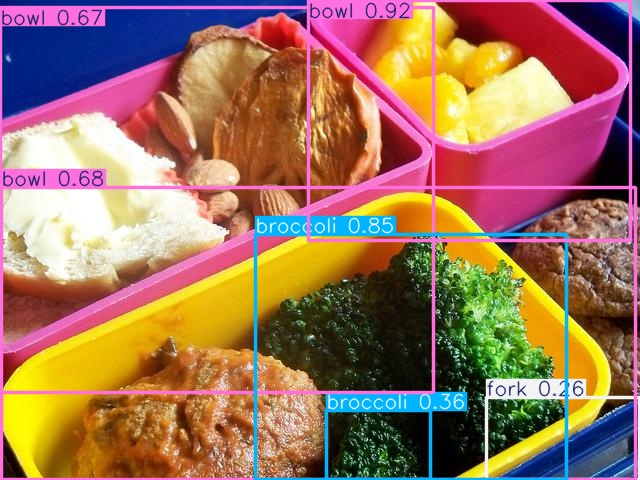

  000000000025.jpg: giraffe (0.88)


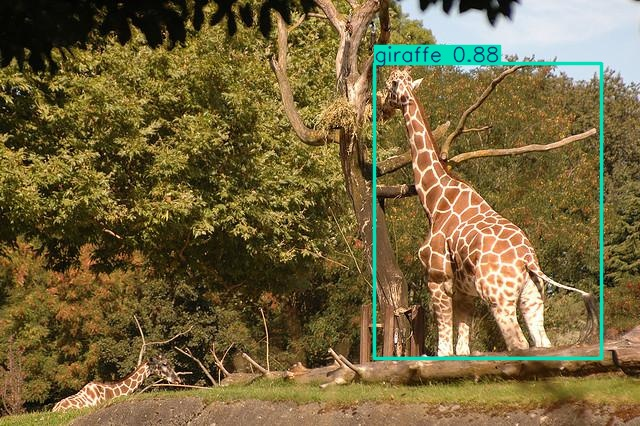

  000000000030.jpg: vase (0.89), potted plant (0.64)


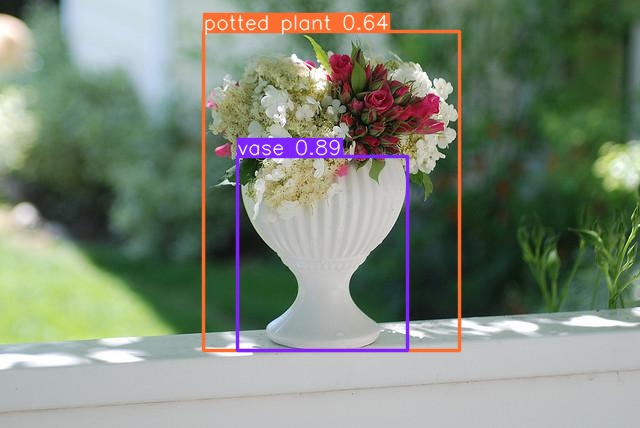

In [4]:
# STAGE 1: Evaluate original COCO128 images
import yaml, cv2, numpy as np, pandas as pd
from IPython.display import display, Image as IPImage

ORIG_IMAGES = dataset_dir / 'images' / 'train2017'
ORIG_LABELS = dataset_dir / 'labels' / 'train2017'
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}
original_files = sorted(p for p in ORIG_IMAGES.iterdir() if p.suffix.lower() in IMAGE_EXTS)
assert len(original_files) >= 3, 'COCO128 images missing; run the download setup cell.'
assert ORIG_LABELS.is_dir(), 'Original labels directory is missing.'
# Use identical filenames at all three stages so comparisons are matched.
example_names = [p.name for p in original_files[:3]]
STATS = {}
PREDICTIONS = {}


def write_dataset_yaml(root, name):
    # YOLO expects images/<split> and labels/<split> sibling directories.
    cfg = {'path': str(root.resolve()), 'train': 'images/train2017',
           'val': 'images/train2017', 'nc': len(model.names),
           'names': {int(k): v for k, v in model.names.items()}}
    file = PROJECT_ROOT / f'{name}_dataset.yaml'
    with file.open('w') as f:
        yaml.safe_dump(cfg, f, sort_keys=False)
    return file


def evaluate_stage(stage, root, yaml_file):
    validation = model.val(data=str(yaml_file), split='val', imgsz=640,
                           batch=16, workers=0, verbose=False, plots=False,
                           project=str(PROJECT_ROOT / 'validation'), name=stage, exist_ok=True)
    m = validation.box
    STATS[stage] = {'Precision': float(m.mp), 'Recall': float(m.mr),
                    'mAP@0.5': float(m.map50), 'mAP@0.5:0.95': float(m.map)}
    print(stage, ', '.join(f'{x:.4f}' for x in STATS[stage].values()))

    pred_dir = PROJECT_ROOT / 'prediction_examples' / stage
    pred_dir.mkdir(parents=True, exist_ok=True)
    examples = []
    for fname in example_names:
        img = root / 'images' / 'train2017' / fname
        results = model.predict(source=str(img), imgsz=640, conf=0.25,
                                verbose=False, save=False)[0]
        out = pred_dir / fname
        ok = cv2.imwrite(str(out), results.plot())
        assert ok, f'Could not save {out}'
        detections = []
        for box in results.boxes:
            label = model.names[int(box.cls.item())]
            confidence = float(box.conf.item())
            detections.append((label, confidence))
        desc = ', '.join(f'{label} ({confidence:.2f})' for label, confidence in detections) or 'No detections at conf=0.25'
        examples.append({'image': fname, 'detections': desc, 'path': str(out)})
        print(f'  {fname}: {desc}')
        display(IPImage(filename=str(out), width=550))
    PREDICTIONS[stage] = examples
    return validation

orig_yaml = write_dataset_yaml(dataset_dir, 'original')
orig_result = evaluate_stage('Original', dataset_dir, orig_yaml)



# Stage 2 — Gaussian Blur

Create a blurred copy of **all COCO128 images**.

### Required blur setting
Use a **9 × 9 Gaussian kernel** with standard OpenCV Gaussian blur.

### Your task
1. Read every original image.
2. Apply Gaussian blur.
3. Save the blurred image with the same filename.
4. Keep the same labels.
5. Evaluate the same YOLO11n detector on the blurred dataset.
6. Record the same four metrics.
7. Save at least **3 blurred prediction examples**.

Do not retrain or replace the detector.


Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5344.4±2129.1 MB/s, size: 51.2 KB)
val: Scanning /content/fvl_project/blurred/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 4.6Kit/s 0.0s
val: New cache created: /content/fvl_project/blurred/labels/train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 25.7it/s 0.3s
                   all        128        929      0.679      0.537      0.617      0.445
Speed: 0.1ms preprocess, 0.3ms inference, 0.0ms loss, 0.3ms postprocess per image
Blurred 0.6789, 0.5368, 0.6173, 0.4445
  000000000009.jpg: bowl (0.92), broccoli (0.88), bowl (0.68), bowl (0.60), bowl (0.60), fork (0.38)


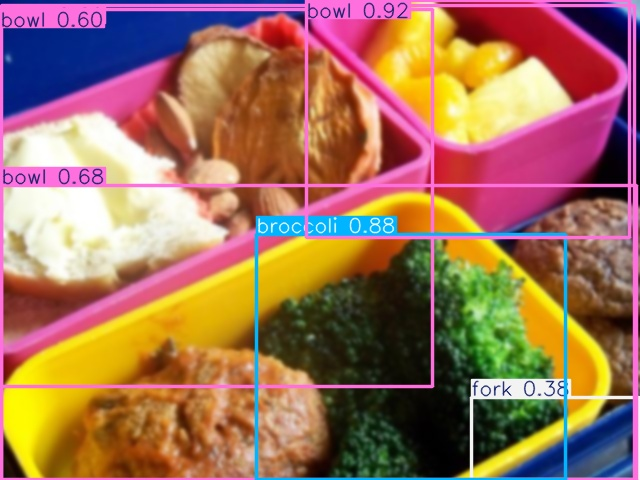

  000000000025.jpg: giraffe (0.87)


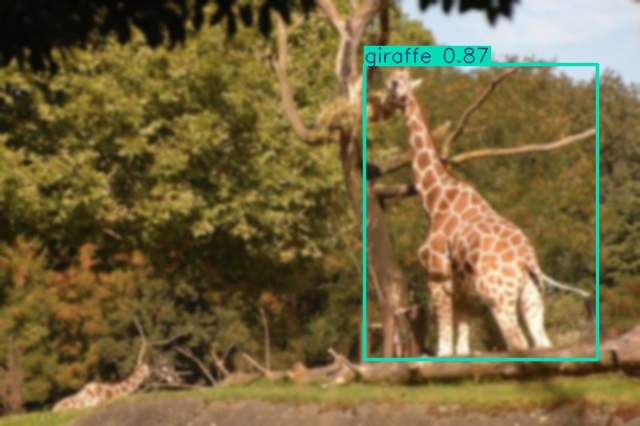

  000000000030.jpg: vase (0.88), potted plant (0.69)


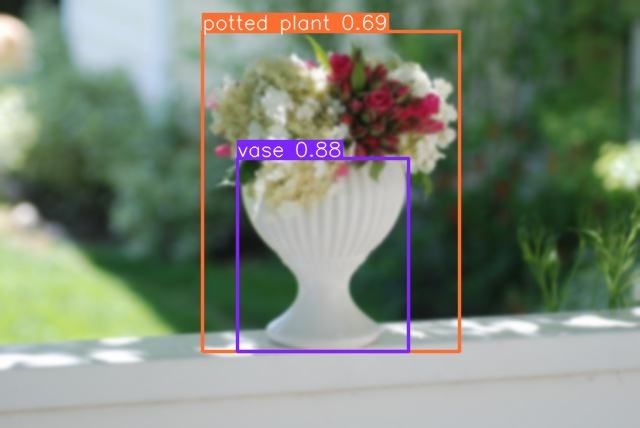

In [5]:
# STAGE 2: 9x9 Gaussian Blur applied to all original images
import shutil
BLURRED_ROOT = PROJECT_ROOT / 'blurred'
blur_images = BLURRED_ROOT / 'images' / 'train2017'
blur_labels = BLURRED_ROOT / 'labels' / 'train2017'
blur_images.mkdir(parents=True, exist_ok=True)
blur_labels.mkdir(parents=True, exist_ok=True)
for original in original_files:
    image = cv2.imread(str(original))
    if image is None:
        raise ValueError(f'Cannot read image: {original}')
    blurred = cv2.GaussianBlur(image, (9, 9), 0)
    if not cv2.imwrite(str(blur_images / original.name), blurred):
        raise IOError(f'Cannot save blurred image: {original.name}')
    label = ORIG_LABELS / f'{original.stem}.txt'
    if label.exists():
        shutil.copy2(label, blur_labels / label.name)
assert len(list(blur_images.iterdir())) == len(original_files)
blur_yaml = write_dataset_yaml(BLURRED_ROOT, 'blurred')
blur_result = evaluate_stage('Blurred', BLURRED_ROOT, blur_yaml)



# Stage 3 — Sharpen the Blurred Images

Apply **one sharpening method** to the Stage 2 blurred images.

You may use a standard sharpening kernel or unsharp masking. Keep the image size unchanged.

### Your task
1. Implement the sharpening operation yourself.
2. Apply it to every blurred image.
3. Save the sharpened images with the same filenames.
4. Keep the same labels.
5. Evaluate the same YOLO11n detector again.
6. Record the same four metrics.
7. Save at least **3 sharpened prediction examples**.

Do not retrain or replace YOLO11n.


Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5832.9±1419.1 MB/s, size: 59.7 KB)
val: Scanning /content/fvl_project/sharpened/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 4.7Kit/s 0.0s
val: New cache created: /content/fvl_project/sharpened/labels/train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 25.4it/s 0.3s
                   all        128        929      0.646      0.551       0.62      0.449
Speed: 0.1ms preprocess, 0.3ms inference, 0.0ms loss, 0.3ms postprocess per image
Sharpened 0.6465, 0.5515, 0.6200, 0.4490
  000000000009.jpg: bowl (0.92), broccoli (0.88), bowl (0.67), bowl (0.60), bowl (0.59), fork (0.36)


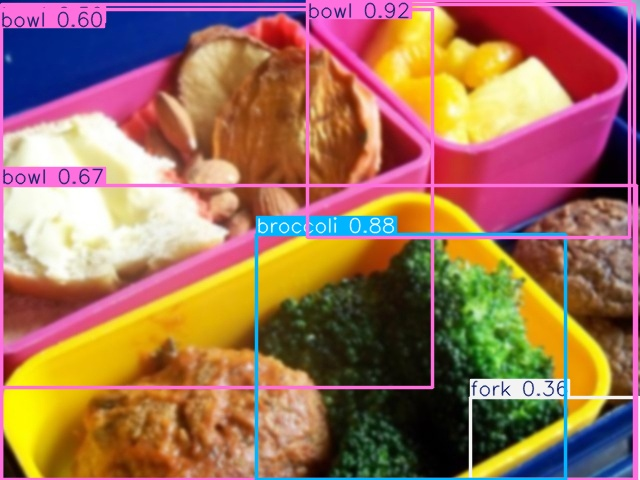

  000000000025.jpg: giraffe (0.87)


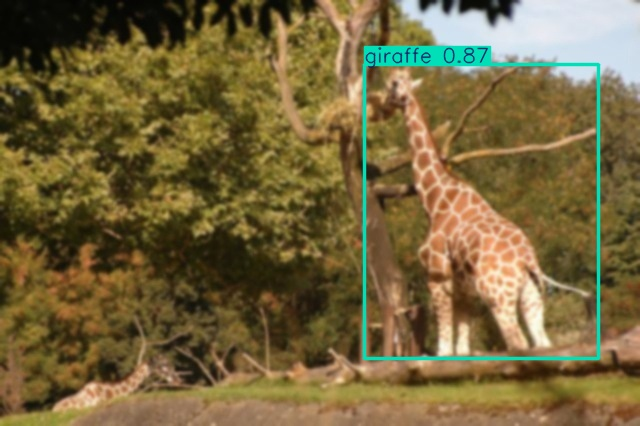

  000000000030.jpg: vase (0.87), potted plant (0.70)


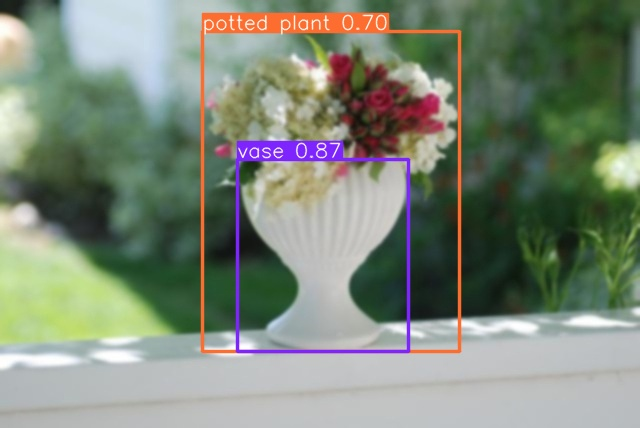

In [6]:
# STAGE 3: Unsharp masking on blurred images (no retraining)
SHARPENED_ROOT = PROJECT_ROOT / 'sharpened'
sharp_images = SHARPENED_ROOT / 'images' / 'train2017'
sharp_labels = SHARPENED_ROOT / 'labels' / 'train2017'
sharp_images.mkdir(parents=True, exist_ok=True)
sharp_labels.mkdir(parents=True, exist_ok=True)
# Unsharp mask: sharp = 1.5 * blurred - 0.5 * GaussianBlur(blurred, (0,0), 1.0)
for original in original_files:
    blurred = cv2.imread(str(blur_images / original.name))
    assert blurred is not None, f'Cannot read blurred image: {original.name}'
    low_frequency = cv2.GaussianBlur(blurred, (0, 0), sigmaX=1.0)
    sharpened = cv2.addWeighted(blurred, 1.5, low_frequency, -0.5, 0)
    if not cv2.imwrite(str(sharp_images / original.name), sharpened):
        raise IOError(f'Cannot save sharpened image: {original.name}')
    label = ORIG_LABELS / f'{original.stem}.txt'
    if label.exists():
        shutil.copy2(label, sharp_labels / label.name)
assert len(list(sharp_images.iterdir())) == len(original_files)
sharp_yaml = write_dataset_yaml(SHARPENED_ROOT, 'sharpened')
sharp_result = evaluate_stage('Sharpened', SHARPENED_ROOT, sharp_yaml)


# Stage 4 — Final Results and Google Form answers

Run the next cell **after Stages 1–3**. It prints actual values to **four decimal places**, three matched prediction examples per stage, and evidence-based answers A–D. Copy the values into the Google Form. Never submit blank/assumed results.


In [7]:
# Generate results and form answers from actual model outputs
assert all(s in STATS and s in PREDICTIONS for s in ['Original','Blurred','Sharpened']), 'Run all three stages first.'
stages = ['Original', 'Blurred', 'Sharpened']
df = pd.DataFrame.from_dict(STATS, orient='index').loc[stages]
print('FINAL RESULTS MATRIX')
display(df.style.format('{:.4f}'))

rows = ['Name: Alok Sahni', 'Roll number: G25AIT2138', 'Email: g25ait2138@iitj.ac.in']
for s in stages:
    vals = ', '.join(f'{x:.4f}' for x in df.loc[s].values)
    rows.append(f'Result — {s}: {vals}')
    preds = '; '.join(f"{p['image']}: {p['detections']}" for p in PREDICTIONS[s])
    rows.append(f'Prediction examples — {s}: {preds}')

def metrics_diff(stage_from, stage_to):
    return {k: STATS[stage_to][k] - STATS[stage_from][k] for k in df.columns}

def comparison(diff):
    return '; '.join(f'{key}: {diff[key]:+.4f}' for key in df.columns)

blur_diff = metrics_diff('Original', 'Blurred')
sharp_diff = metrics_diff('Blurred', 'Sharpened')
a = ('A. Effect of blur: Original → Gaussian Blur metric changes: ' + comparison(blur_diff) +
     '. Gaussian blur (9×9) suppresses fine detail and edges; see matched examples: ' +
     '; '.join(f"{PREDICTIONS['Original'][i]['image']} — original [{PREDICTIONS['Original'][i]['detections']}], blurred [{PREDICTIONS['Blurred'][i]['detections']}]" for i in range(3)) +
     '. Positive changes denote increases; negative changes denote decreases.')
b = ('B. Why sharpening? Applied unsharp masking to each blurred image: '
     'sharpened = 1.5×blurred − 0.5×GaussianBlur(blurred, σ=1.0). '
     'This boosts local contrast around edges and may make object boundaries easier for YOLO11n to detect. '
     'It cannot fully reconstruct details lost during blur.')
improved = [k for k,v in sharp_diff.items() if v > 0.0000001]
worse = [k for k,v in sharp_diff.items() if v < -0.0000001]
unchanged = [k for k,v in sharp_diff.items() if abs(v) <= 0.0000001]
c = ('C. Did sharpening help? Blurred → Sharpened metric changes: ' + comparison(sharp_diff) +
     '. Improved: ' + (', '.join(improved) or 'none') +
     '. Worsened: ' + (', '.join(worse) or 'none') +
     '. Unchanged: ' + (', '.join(unchanged) or 'none') +
     '. Matched detections: ' +
     '; '.join(f"{PREDICTIONS['Blurred'][i]['image']} — blurred [{PREDICTIONS['Blurred'][i]['detections']}], sharpened [{PREDICTIONS['Sharpened'][i]['detections']}]" for i in range(3)) + '.')
keep = sharp_diff['mAP@0.5:0.95'] > 0 and sharp_diff['mAP@0.5'] >= 0
d = ('D. Final conclusion: ' +
     ('I would retain unsharp masking for this tested setting, because mAP@0.5:0.95 increased and mAP@0.5 did not decrease relative to blur.' if keep else
      'I would not retain unsharp masking as the default, since it did not improve mAP@0.5:0.95 without lowering mAP@0.5 relative to blur.') +
     ' The conclusion is specific to COCO128, YOLO11n, and the chosen settings; compare images and test on more data before generalizing.')
rows += [a,b,c,d]
form_text = '\n\n'.join(rows)
print('\nGOOGLE FORM — COPY READY\n')
print(form_text)
(PROJECT_ROOT / 'G25AIT2138_CV_Google_Form_Answers.txt').write_text(form_text, encoding='utf-8')
df.to_csv(PROJECT_ROOT / 'G25AIT2138_CV_final_metrics.csv', float_format='%.4f')
print('\nSaved form answers and metrics in:', PROJECT_ROOT)


FINAL RESULTS MATRIX


,Precision,Recall,mAP@0.5,mAP@0.5:0.95
Original,0.6599,0.5886,0.6703,0.5026
Blurred,0.6789,0.5368,0.6173,0.4445
Sharpened,0.6465,0.5515,0.6200,0.4490



GOOGLE FORM — COPY READY

Name: Alok Sahni

Roll number: G25AIT2138

Email: g25ait2138@iitj.ac.in

Result — Original: 0.6599, 0.5886, 0.6703, 0.5026

Prediction examples — Original: 000000000009.jpg: bowl (0.92), broccoli (0.85), bowl (0.68), bowl (0.67), broccoli (0.36), fork (0.26); 000000000025.jpg: giraffe (0.88); 000000000030.jpg: vase (0.89), potted plant (0.64)

Result — Blurred: 0.6789, 0.5368, 0.6173, 0.4445

Prediction examples — Blurred: 000000000009.jpg: bowl (0.92), broccoli (0.88), bowl (0.68), bowl (0.60), bowl (0.60), fork (0.38); 000000000025.jpg: giraffe (0.87); 000000000030.jpg: vase (0.88), potted plant (0.69)

Result — Sharpened: 0.6465, 0.5515, 0.6200, 0.4490

Prediction examples — Sharpened: 000000000009.jpg: bowl (0.92), broccoli (0.88), bowl (0.67), bowl (0.60), bowl (0.59), fork (0.36); 000000000025.jpg: giraffe (0.87); 000000000030.jpg: vase (0.87), potted plant (0.70)

A. Effect of blur: Original → Gaussian Blur metric changes: Precision: +0.0190; Recall: -

## Verification before submission

- Confirm all three metric rows are populated by actual validation runs.
- Check 3 plotted prediction examples for **each** stage (9 images total), using identical image filenames.
- Compare detection classes and confidence carefully; reported text is raw predictions, not a guaranteed ground-truth correctness assessment.
- Download **this executed notebook** from Colab and submit it along with the separate Google Form.
- The text file generated by Stage 4 is for copy/paste; this notebook does **not** submit the form automatically.



# Submission

Submit:
1. Completed `.ipynb` with final results table and with at least 3 prediction examples from each stage: Original, Blurred, Sharpened
2. Google Form for Results, Prediction examples and Analysis submission

Use your roll number in every submitted filename.
Students are requested to submit in time 1 marks will be deducted per day for late submission

Deadline: Sun, 25 October 2026, 11:59 P.M.
